In [10]:
import pathlib

import matplotlib.pyplot as plt
import pandas as pd

In [11]:
LOG_PATH = pathlib.Path("/tmp/1780319662")

In [12]:
def read_hc_logs(path: str):
    with open(path, "r") as readable:
        df_logs = pd.read_json(readable, lines=True)
    df_logs["q_total"] = df_logs["h"] + df_logs["c"]
    return df_logs

In [13]:
df_logs = read_hc_logs(LOG_PATH)

In [14]:
df_logs.head()

,episode,step,h,c,true_episode_return,q_total
0,0,0,-1.023708,-10.146957,-5.200085,-11.170666
1,0,1,-1.525912,-9.628538,-5.200085,-11.154450
2,0,2,-1.938905,-9.185055,-5.200085,-11.123960
3,0,3,-2.224754,-8.945518,-5.200085,-11.170271
4,0,4,-2.417271,-8.810629,-5.200085,-11.227900


In [ ]:
def plot_hc_contrib(df_input: pd.DataFrame):
    episodes = sorted(df_input["episode"].unique())
    num_episodes = len(episodes)
    ncols = min(3, num_episodes)
    nrows = (num_episodes + ncols - 1) // ncols

    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4 * nrows), squeeze=False)

    for idx, ep in enumerate(episodes):
        ax = axes[idx // ncols][idx % ncols]
        ep_df = df_input[df_input["episode"] == ep]
        steps = ep_df["step"].values

        ax.plot(steps, ep_df["c"].values, label="Critic $Q^C$", alpha=0.8)
        ax.plot(steps, ep_df["h"].values, label="History $Q^H$", alpha=0.8)
        ax.plot(steps, ep_df["q_total"].values, label="$Q^H + Q^C$", alpha=0.8)
        ax.axhline(
            ep_df["true_episode_return"].iloc[0],
            color="k",
            linestyle="--",
            linewidth=1,
            label="True return",
        )

        ax.set_title(f"Episode {ep}")
        ax.set_xlabel("Step")
        ax.set_ylabel("Value")
        if idx == 0:
            ax.legend(fontsize=8)

    # hide unused axes
    for idx in range(num_episodes, nrows * ncols):
        axes[idx // ncols][idx % ncols].set_visible(False)

    fig.suptitle("HC Prediction Logs: Critic, History, and True Return", fontsize=14, y=1.01)
    fig.tight_layout()
    plt.show()

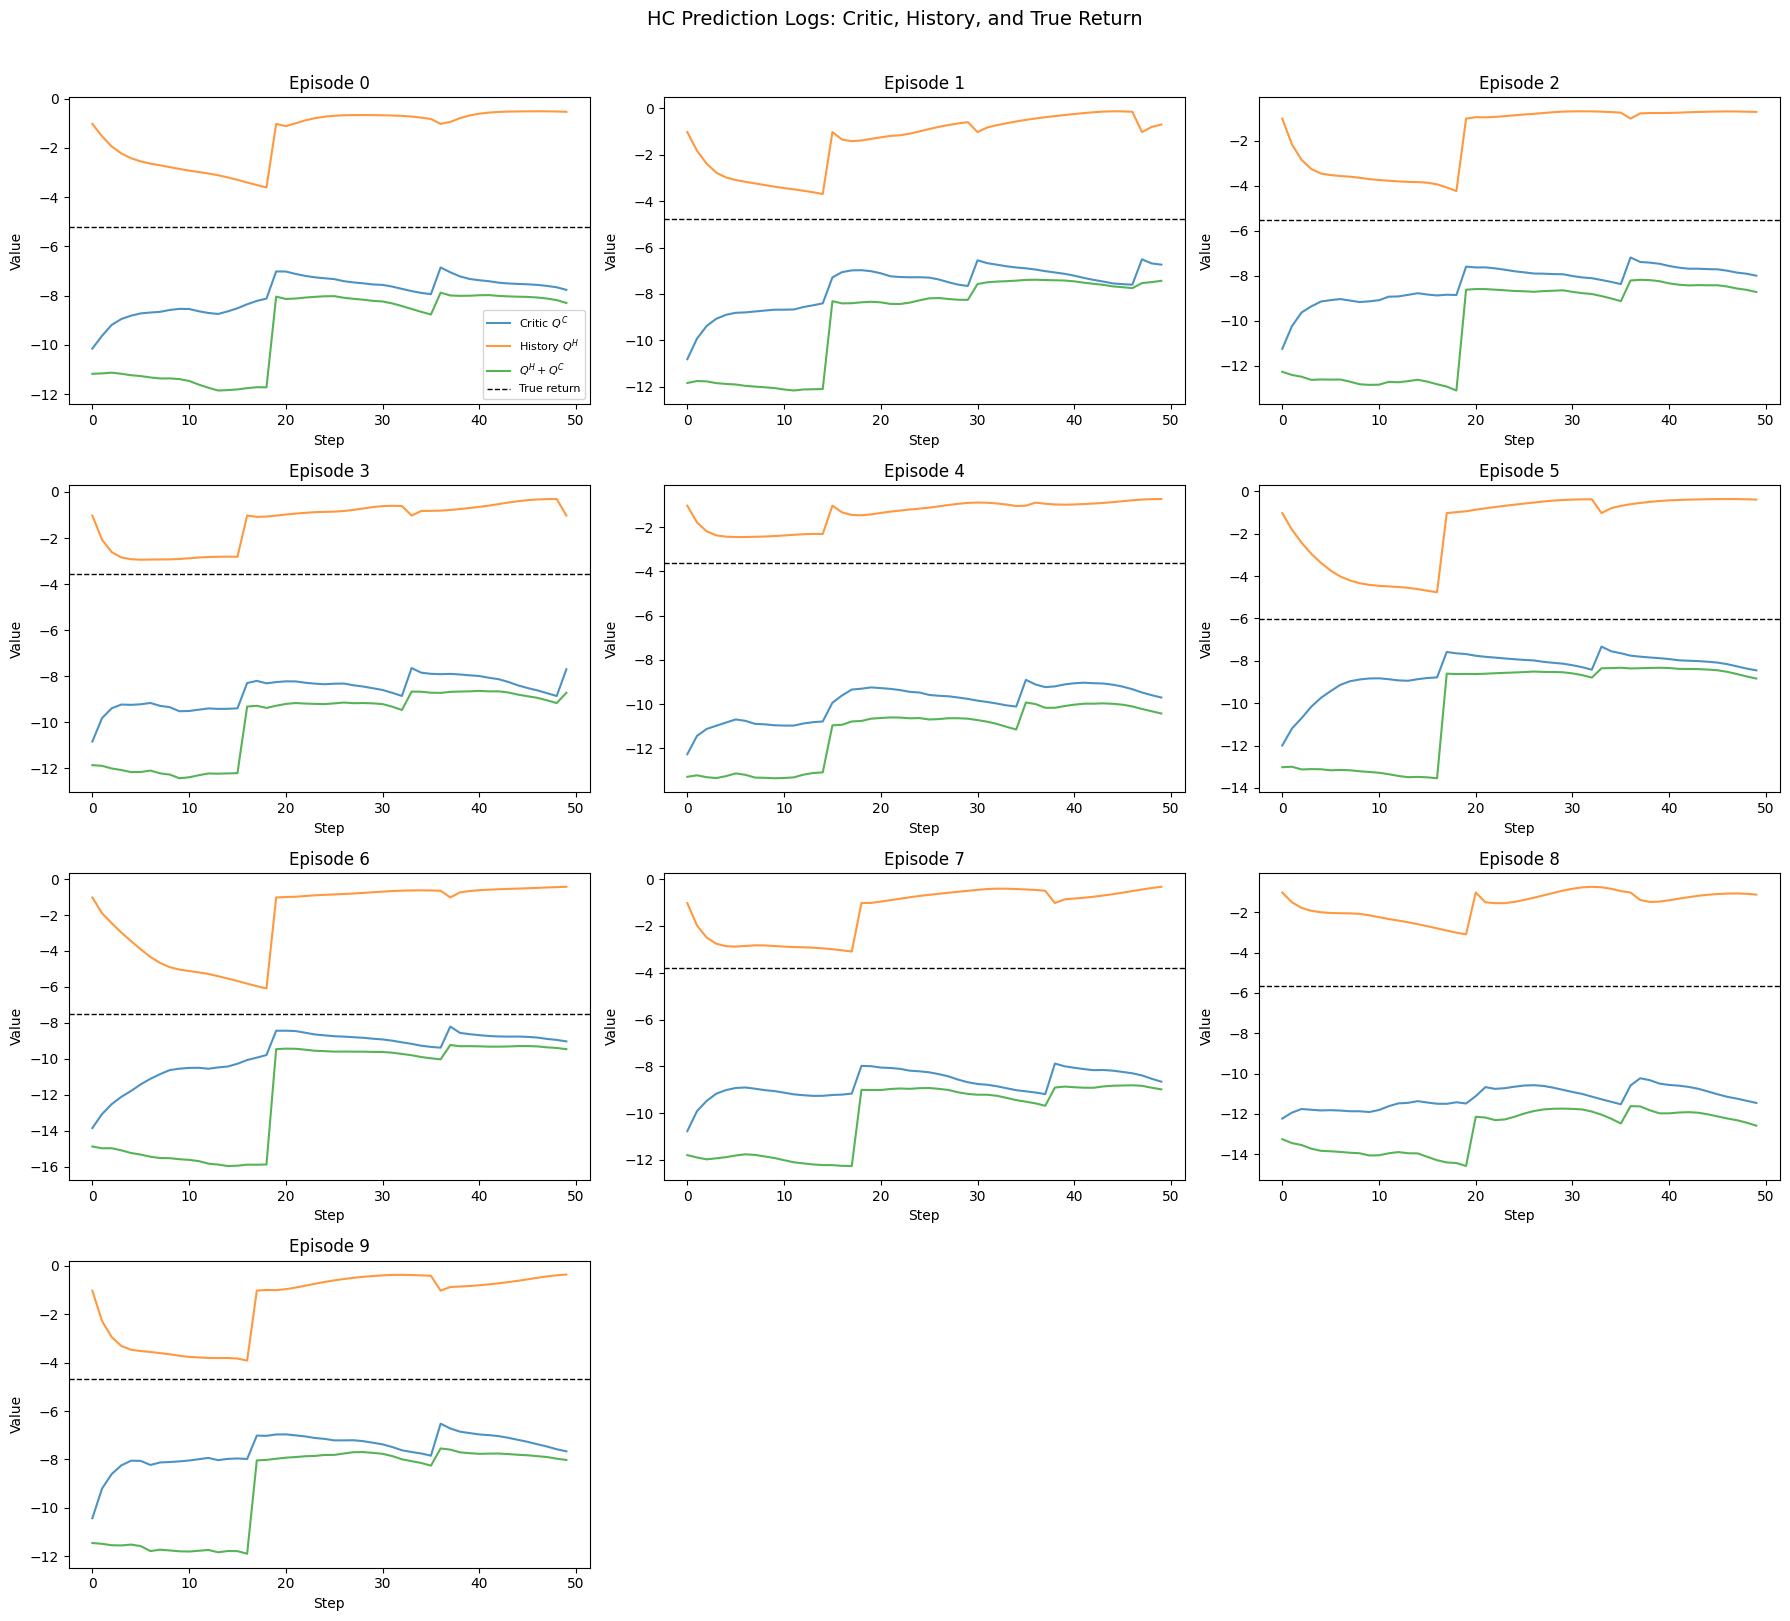

In [16]:
plot_hc_contrib(df_logs)